<a href="https://colab.research.google.com/github/reshmiee/codemixing_llmrouter/blob/main/person4_RouteLLM_Benchmark_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pandas numpy scikit-learn scipy joblib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/ML_Research"

print(os.listdir(BASE))

Mounted at /content/drive
['data', 'scores', 'features', 'results', '_dryrun', 'dataset']


In [ ]:
for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/drive/MyDrive/ML_Research/data/confirmatory_v1.csv
/content/drive/MyDrive/ML_Research/data/ood_scrambled_texts_v1.csv
/content/drive/MyDrive/ML_Research/scores/scores_v1.csv
/content/drive/MyDrive/ML_Research/scores/scores_v2.csv
/content/drive/MyDrive/ML_Research/scores/scores_confirmatory_v1.csv
/content/drive/MyDrive/ML_Research/scores/scores_triple_v1.csv
/content/drive/MyDrive/ML_Research/scores/scores_ood_scrambled_v1.csv
/content/drive/MyDrive/ML_Research/features/features_v1.csv
/content/drive/MyDrive/ML_Research/features/features_v2.csv
/content/drive/MyDrive/ML_Research/features/features_v3.csv
/content/drive/MyDrive/ML_Research/features/p3_features_v1.csv
/content/drive/MyDrive/ML_Research/features/features_confirmatory_v1.csv
/content/drive/MyDrive/ML_Research/features/features_triple_v1.csv
/content/drive/MyDrive/ML_Research/results/routing_gap_v1.csv
/content/drive/MyDrive/ML_Research/results/gap_by_difficulty_v1.csv
/content/drive/MyDrive/ML_Research/results/gap

In [ ]:
import pandas as pd
import os

files_to_check = [
    "scores/scores_v1.csv",
    "scores/scores_v2.csv",
    "scores/scores_confirmatory_v1.csv",
    "features/features_v1.csv",
    "features/features_v2.csv",
    "features/features_v3.csv",
    "features/p3_features_v1.csv",
    "features/features_confirmatory_v1.csv"
]

for file in files_to_check:
    path = os.path.join(BASE, file)
    df = pd.read_csv(path)

    print("\nFILE:", file)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(2))


FILE: scores/scores_v1.csv
Shape: (80, 4)
Columns: ['pair_id', 'english_score', 'hinglish_score', 'diff_en_minus_hi']


,pair_id,english_score,hinglish_score,diff_en_minus_hi
0,1,0.249989,0.280707,-0.030718
1,2,0.205350,0.336730,-0.131379



FILE: scores/scores_v2.csv
Shape: (80, 4)
Columns: ['pair_id', 'english_score', 'hinglish_score', 'diff_en_minus_hi']


,pair_id,english_score,hinglish_score,diff_en_minus_hi
0,1,0.249989,0.280707,-0.030718
1,2,0.205350,0.336730,-0.131379



FILE: scores/scores_confirmatory_v1.csv
Shape: (152, 7)
Columns: ['pair_id', 'english_score', 'hinglish_score', 'diff_en_minus_hi', 'task_type', 'difficulty', 'written_by']


...

,pair_id,en_words,en_tokens,en_fertility,hi_words,hi_tokens,hi_fertility,tokens_diff_hi_minus_en,tokens_diff_en_minus_hi,words_diff_en_minus_hi,fert_diff_en_minus_hi
0,1,10,14,1.400000,9,13,1.444444,-1,1,1,-0.044444
1,2,9,10,1.111111,8,9,1.125000,-1,1,1,-0.013889



FILE: features/p3_features_v1.csv
Shape: (80, 13)
Columns: ['pair_id', 'en_tokens', 'en_words', 'en_fertility', 'en_rare', 'hi_tokens', 'hi_words', 'hi_fertility', 'hi_rare', 'd_tokens', 'd_words', 'd_fertility', 'd_rare']


,pair_id,en_tokens,en_words,en_fertility,en_rare,hi_tokens,hi_words,hi_fertility,hi_rare,d_tokens,d_words,d_fertility,d_rare
0,1,14,10,1.400000,0,13,9,1.444444,0,1,1,-0.044444,0
1,2,10,9,1.111111,0,9,8,1.125000,0,1,1,-0.013889,0



FILE: features/features_confirmatory_v1.csv
Shape: (152, 10)
Columns: ['pair_id', 'english_words', 'english_tokens', 'english_fertility', 'hinglish_words', 'hinglish_tokens', 'hinglish_fertility', 'tokens_diff_en_minus_hi', 'words_diff_en_minus_hi', 'fert_diff_en_minus_hi']


,pair_id,english_words,english_tokens,english_fertility,hinglish_words,hinglish_tokens,hinglish_fertility,tokens_diff_en_minus_hi,words_diff_en_minus_hi,fert_diff_en_minus_hi
0,101,21,41,1.952381,29,49,1.689655,-8,-8,0.262726
1,102,14,28,2.000000,16,29,1.812500,-1,-2,0.187500


In [ ]:
for file in files_to_check:
    path = os.path.join(BASE, file)
    df = pd.read_csv(path)

    print("\n", file)

    for col in df.columns:
        if col.lower() in ["id", "pair_id", "question_id"]:
            print("ID column:", col)
            print("First IDs:", df[col].head(5).tolist())
            print("Last IDs:", df[col].tail(5).tolist())


 scores/scores_v1.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 scores/scores_v2.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 scores/scores_confirmatory_v1.csv
ID column: pair_id
First IDs: [101, 102, 103, 104, 105]
Last IDs: [248, 249, 250, 251, 252]

 features/features_v1.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 features/features_v2.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 features/features_v3.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 features/p3_features_v1.csv
ID column: pair_id
First IDs: [1, 2, 3, 4, 5]
Last IDs: [76, 77, 78, 79, 80]

 features/features_confirmatory_v1.csv
ID column: pair_id
First IDs: [101, 102, 103, 104, 105]
Last IDs: [248, 249, 250, 251, 252]


In [ ]:
pilot_scores = pd.read_csv(BASE + "/scores/scores_v1.csv")
pilot_features = pd.read_csv(BASE + "/features/features_v3.csv")

test_scores = pd.read_csv(BASE + "/scores/scores_confirmatory_v1.csv")
test_features = pd.read_csv(BASE + "/features/features_confirmatory_v1.csv")

print("Pilot scores:", pilot_scores.shape)
print("Pilot features:", pilot_features.shape)
print("Test scores:", test_scores.shape)
print("Test features:", test_features.shape)

Pilot scores: (80, 4)
Pilot features: (80, 11)
Test scores: (152, 7)
Test features: (152, 10)


In [ ]:
ID_COL = "pair_id"

EN_SCORE = "english_score"
HI_SCORE = "hinglish_score"

PILOT_FEATURE_COLS = ["hi_tokens", "hi_words", "hi_fertility"]
TEST_FEATURE_COLS = [
    "hinglish_tokens",
    "hinglish_words",
    "hinglish_fertility"
]

In [ ]:
pilot_features = pilot_features.rename(columns={
    "hi_tokens": "hinglish_tokens",
    "hi_words": "hinglish_words",
    "hi_fertility": "hinglish_fertility"
})

FEATURE_COLS = [
    "hinglish_tokens",
    "hinglish_words",
    "hinglish_fertility"
]

In [ ]:
pilot = pilot_scores.merge(
    pilot_features[[ID_COL] + FEATURE_COLS],
    on=ID_COL,
    how="inner",
    validate="one_to_one"
)

test = test_scores.merge(
    test_features[[ID_COL] + FEATURE_COLS],
    on=ID_COL,
    how="inner",
    validate="one_to_one"
)

print("Training pairs:", len(pilot))
print("Testing pairs:", len(test))

display(pilot.head())
display(test.head())

Training pairs: 80
Testing pairs: 152


,pair_id,english_score,hinglish_score,diff_en_minus_hi,hinglish_tokens,hinglish_words,hinglish_fertility
0,1,0.249989,0.280707,-0.030718,13,9,1.444444
1,2,0.205350,0.336730,-0.131379,9,8,1.125000
2,3,0.467379,0.443534,0.023845,18,13,1.384615
3,4,0.282970,0.412477,-0.129507,12,10,1.200000
4,5,0.234917,0.288684,-0.053767,13,10,1.300000


,pair_id,english_score,hinglish_score,diff_en_minus_hi,task_type,difficulty,written_by,hinglish_tokens,hinglish_words,hinglish_fertility
0,101,0.593834,0.536935,0.056899,Coding,Easy,A,49,29,1.689655
1,102,0.485699,0.494614,-0.008915,Coding,Easy,A,29,16,1.812500
2,103,0.532111,0.503105,0.029006,Coding,Easy,A,44,26,1.692308
3,104,0.496512,0.507816,-0.011304,Coding,Easy,A,37,19,1.947368
4,105,0.521810,0.519925,0.001885,Coding,Easy,A,41,21,1.952381


In [ ]:
assert len(pilot) == 80, "Pilot dataset should contain 80 pairs"
assert len(test) == 152, "Test dataset should contain 152 pairs"

assert not pilot.duplicated(ID_COL).any()
assert not test.duplicated(ID_COL).any()

assert pilot[FEATURE_COLS + [EN_SCORE, HI_SCORE]].notna().all().all()
assert test[FEATURE_COLS + [EN_SCORE, HI_SCORE]].notna().all().all()

print("Data validation successful.")

Data validation successful.


In [ ]:
from sklearn.preprocessing import StandardScaler

X_train = pilot[[HI_SCORE] + FEATURE_COLS]
y_train = pilot[EN_SCORE]

X_test = test[[HI_SCORE] + FEATURE_COLS]
y_test = test[EN_SCORE]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

gb_model = GradientBoostingRegressor(
    n_estimators=30,
    learning_rate=0.03,
    max_depth=1,
    random_state=42
)

gb_model.fit(X_train_scaled, y_train)

print("Both correction models trained.")

Both correction models trained.


In [ ]:
original_scores = test[HI_SCORE].values

constant_scores = np.full(len(test), y_train.mean())

linear_scores = linear_model.predict(X_test_scaled)

orthogonal_scores = (
    (original_scores - pilot[HI_SCORE].mean())
    * (pilot[EN_SCORE].std() / pilot[HI_SCORE].std())
    + pilot[EN_SCORE].mean()
)

gb_scores = gb_model.predict(X_test_scaled)

predictions = {
    "Original RouteLLM": original_scores,
    "Constant Baseline": constant_scores,
    "Linear Correction": np.clip(linear_scores, 0, 1),
    "Orthogonal Rescaling": np.clip(orthogonal_scores, 0, 1),
    "Gradient Boosting": np.clip(gb_scores, 0, 1)
}

In [ ]:
from sklearn.metrics import mean_absolute_error, cohen_kappa_score

thresholds = {
    "10%": 0.5949,
    "20%": 0.5094,
    "30%": 0.4651,
    "50%": 0.4066,
    "70%": 0.3372
}

results = []

for model_name, scores in predictions.items():
    row = {
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, scores),
        "English SD": np.std(y_test, ddof=1),
        "Corrected SD": np.std(scores, ddof=1),
        "SD Ratio": np.std(y_test, ddof=1) / np.std(scores, ddof=1)
    }

    for threshold_name, threshold in thresholds.items():
        english_route = (y_test >= threshold).astype(int)
        predicted_route = (scores >= threshold).astype(int)

        row[f"{threshold_name} Agreement"] = np.mean(
            english_route == predicted_route
        )

        row[f"{threshold_name} Kappa"] = cohen_kappa_score(
            english_route, predicted_route
        )

    results.append(row)

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,MAE,English SD,Corrected SD,SD Ratio,10% Agreement,10% Kappa,20% Agreement,20% Kappa,30% Agreement,30% Kappa,50% Agreement,50% Kappa,70% Agreement,70% Kappa
0,Original RouteLLM,0.0804,0.1723,0.0892,1.930300e+00,0.8355,0.2765,0.7697,0.5015,0.8947,0.7898,0.8684,0.7154,0.8684,0.6053
1,Constant Baseline,0.1504,0.1723,0.0000,3.093128e+15,0.7961,0.0000,0.5724,0.0000,0.4737,0.0000,0.5987,0.0000,0.7303,0.0000
2,Linear Correction,0.0755,0.1723,0.1412,1.220000e+00,0.8487,0.3564,0.7697,0.5015,0.8158,0.6366,0.9079,0.8114,0.8882,0.7183
3,Orthogonal Rescaling,0.0726,0.1723,0.1588,1.084900e+00,0.8684,0.4832,0.7895,0.5507,0.8882,0.7774,0.8947,0.7821,0.9013,0.7588
4,Gradient Boosting,0.1003,0.1723,0.0656,2.625500e+00,0.7961,0.0000,0.5724,0.0000,0.9013,0.8033,0.8882,0.7601,0.9013,0.7309


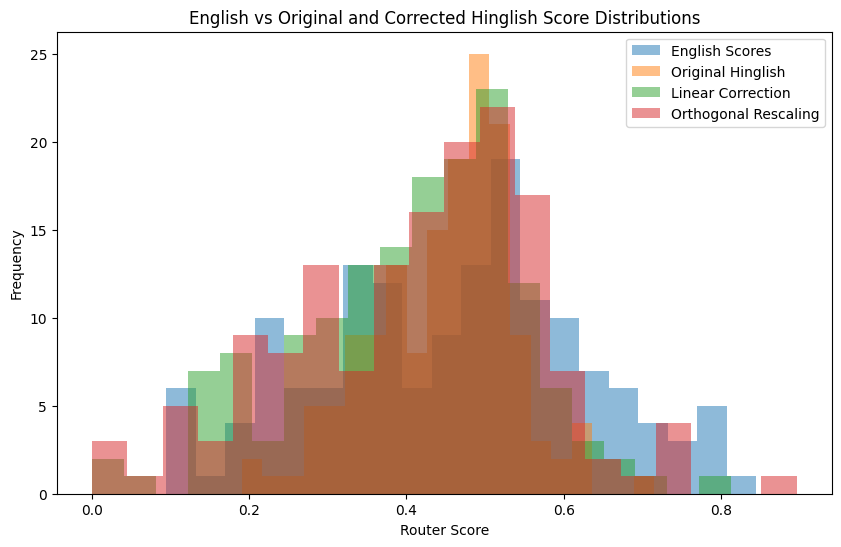

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(y_test, bins=20, alpha=0.5, label="English Scores")
plt.hist(original_scores, bins=20, alpha=0.5, label="Original Hinglish")
plt.hist(predictions["Linear Correction"], bins=20, alpha=0.5, label="Linear Correction")
plt.hist(predictions["Orthogonal Rescaling"], bins=20, alpha=0.5, label="Orthogonal Rescaling")

plt.xlabel("Router Score")
plt.ylabel("Frequency")
plt.title("English vs Original and Corrected Hinglish Score Distributions")
plt.legend()
plt.show()

In [ ]:
OUTPUT_DIR = BASE + "/correction_model_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(
    OUTPUT_DIR + "/model_comparison_v1.csv",
    index=False
)

corrected_df = test[[ID_COL, EN_SCORE, HI_SCORE]].copy()

for name, scores in predictions.items():
    corrected_df[name] = scores

corrected_df.to_csv(
    OUTPUT_DIR + "/corrected_scores_v1.csv",
    index=False
)

print("Results saved to:", OUTPUT_DIR)

Results saved to: /content/drive/MyDrive/ML_Research/correction_model_results


In [ ]:
from sklearn.metrics import mean_absolute_error, cohen_kappa_score

difficulty_results = []

for difficulty in test["difficulty"].unique():
    mask = test["difficulty"] == difficulty

    english = test.loc[mask, EN_SCORE].values

    for model_name in [
        "Original RouteLLM",
        "Linear Correction",
        "Orthogonal Rescaling"
    ]:
        scores = predictions[model_name][mask.values]

        english_route = (english >= 0.4066).astype(int)
        predicted_route = (scores >= 0.4066).astype(int)

        difficulty_results.append({
            "Difficulty": difficulty,
            "Model": model_name,
            "Pairs": len(english),
            "MAE": mean_absolute_error(english, scores),
            "50% Agreement": np.mean(english_route == predicted_route),
            "50% Kappa": cohen_kappa_score(
                english_route, predicted_route
            )
        })

difficulty_df = pd.DataFrame(difficulty_results)

display(
    difficulty_df.round(4).sort_values(
        ["Difficulty", "Model"]
    )
)

,Difficulty,Model,Pairs,MAE,50% Agreement,50% Kappa
1,Easy,Linear Correction,76,0.0870,0.9211,0.8421
0,Easy,Original RouteLLM,76,0.0930,0.8289,0.6579
2,Easy,Orthogonal Rescaling,76,0.0810,0.8947,0.7895
4,Hard,Linear Correction,76,0.0640,0.8947,0.7623
3,Hard,Original RouteLLM,76,0.0679,0.9079,0.7734
5,Hard,Orthogonal Rescaling,76,0.0641,0.8947,0.7678


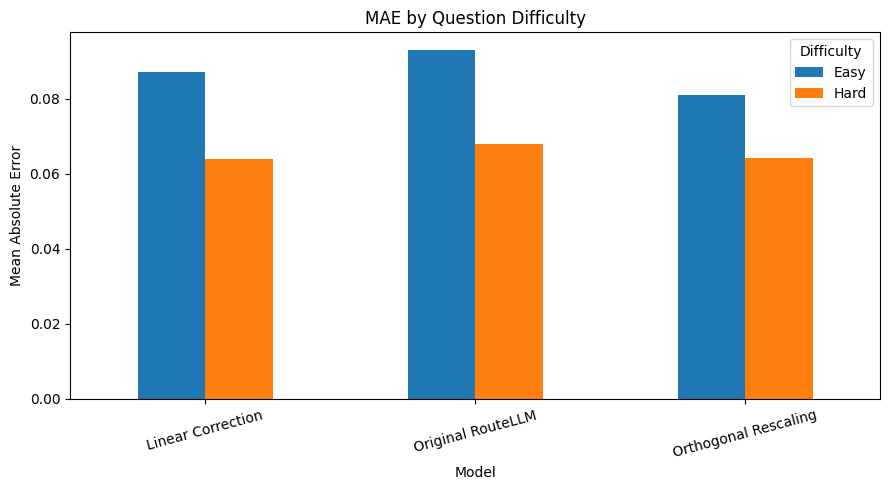

In [ ]:
difficulty_pivot = difficulty_df.pivot(
    index="Model",
    columns="Difficulty",
    values="MAE"
)

difficulty_pivot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("MAE by Question Difficulty")
plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.legend(title="Difficulty")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.utils import resample

def bootstrap_mae_improvement(original, corrected, n_boot=5000):
    improvements = []

    original = np.asarray(original)
    corrected = np.asarray(corrected)

    for _ in range(n_boot):
        indices = np.random.choice(
            len(original), len(original), replace=True
        )

        original_mae = np.mean(
            np.abs(y_test.values[indices] - original[indices])
        )

        corrected_mae = np.mean(
            np.abs(y_test.values[indices] - corrected[indices])
        )

        improvements.append(original_mae - corrected_mae)

    return (
        np.mean(improvements),
        np.percentile(improvements, 2.5),
        np.percentile(improvements, 97.5)
    )


for model in ["Linear Correction", "Orthogonal Rescaling"]:
    mean_imp, lower, upper = bootstrap_mae_improvement(
        original_scores,
        predictions[model]
    )

    print(f"\n{model}")
    print(f"Mean MAE improvement: {mean_imp:.4f}")
    print(f"95% CI: [{lower:.4f}, {upper:.4f}]")


Linear Correction
Mean MAE improvement: 0.0048
95% CI: [-0.0036, 0.0134]

Orthogonal Rescaling
Mean MAE improvement: 0.0079
95% CI: [-0.0002, 0.0161]


In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

threshold = 0.4066

english_route = (y_test.values >= threshold).astype(int)

original_correct = (
    (original_scores >= threshold).astype(int) == english_route
)

for model in ["Linear Correction", "Orthogonal Rescaling"]:
    corrected_route = (
        predictions[model] >= threshold
    ).astype(int)

    corrected_correct = corrected_route == english_route

    table = [
        [
            np.sum(original_correct & corrected_correct),
            np.sum(original_correct & ~corrected_correct)
        ],
        [
            np.sum(~original_correct & corrected_correct),
            np.sum(~original_correct & ~corrected_correct)
        ]
    ]

    result = mcnemar(table, exact=True)

    print(f"\n{model}")
    print("Contingency table:", table)
    print("McNemar p-value:", result.pvalue)


Linear Correction
Contingency table: [[np.int64(124), np.int64(8)], [np.int64(14), np.int64(6)]]
McNemar p-value: 0.28627872467041016

Orthogonal Rescaling
Contingency table: [[np.int64(126), np.int64(6)], [np.int64(10), np.int64(10)]]
McNemar p-value: 0.454498291015625


In [ ]:
final_comparison = results_df[
    [
        "Model",
        "MAE",
        "SD Ratio",
        "10% Agreement",
        "20% Agreement",
        "30% Agreement",
        "50% Agreement",
        "50% Kappa",
        "70% Agreement"
    ]
].copy()

display(final_comparison.round(4))

,Model,MAE,SD Ratio,10% Agreement,20% Agreement,30% Agreement,50% Agreement,50% Kappa,70% Agreement
0,Original RouteLLM,0.0804,1.930300e+00,0.8355,0.7697,0.8947,0.8684,0.7154,0.8684
1,Constant Baseline,0.1504,3.093128e+15,0.7961,0.5724,0.4737,0.5987,0.0000,0.7303
2,Linear Correction,0.0755,1.220000e+00,0.8487,0.7697,0.8158,0.9079,0.8114,0.8882
3,Orthogonal Rescaling,0.0726,1.084900e+00,0.8684,0.7895,0.8882,0.8947,0.7821,0.9013
4,Gradient Boosting,0.1003,2.625500e+00,0.7961,0.5724,0.9013,0.8882,0.7601,0.9013


In [ ]:
final_comparison.to_csv(
    OUTPUT_DIR + "/final_model_comparison.csv",
    index=False
)

difficulty_df.to_csv(
    OUTPUT_DIR + "/difficulty_analysis.csv",
    index=False
)

print("Final research tables saved successfully.")
print("Output directory:", OUTPUT_DIR)

Final research tables saved successfully.
Output directory: /content/drive/MyDrive/ML_Research/correction_model_results
